In [3]:
from functools import partial
import numpy as np
import pandas as pd

from cwfc.targets import load_cpu_readings, build_targets, split_train_holdout
from cwfc.baselines import (persistence_forecast, seasonal_naive_forecast,
                            moving_average_forecast, training_mean_forecast)
from cwfc.evaluate import evaluate_forecaster, summarize, collect_predictions

cpu = load_cpu_readings("../challenge_data")
targets = build_targets(cpu)
train, holdout = split_train_holdout(targets)    # only `train` is used below
assert len(train) == 110

baselines = {
    "persistence":       persistence_forecast,
    "moving_avg_3":      partial(moving_average_forecast, window=3),
    "moving_avg_6":      partial(moving_average_forecast, window=6),
    "moving_avg_12":     partial(moving_average_forecast, window=12),
    "training_mean":     training_mean_forecast,
    "seasonal_naive_12": partial(seasonal_naive_forecast, season_length=12),
    "seasonal_naive_24": partial(seasonal_naive_forecast, season_length=24),
}

In [4]:
from cwfc.models import mean_reverting_forecast, ridge_direct_forecast

T = "aggregate_cpu_utilization"
candidates = {
    "ar1_mean_reverting": mean_reverting_forecast,
    "ridge_a0.01": partial(ridge_direct_forecast, alpha=0.01),
    "ridge_a0.1":  partial(ridge_direct_forecast, alpha=0.1),
    "ridge_a1":    partial(ridge_direct_forecast, alpha=1.0),
    "persistence":   baselines["persistence"],
    "training_mean": baselines["training_mean"],
}

def run(**kw):
    return pd.DataFrame({n: summarize(evaluate_forecaster(train, f, T, **kw)[1])
                         for n, f in candidates.items()}).T.round(4)

print("PRIMARY (4 folds)");       print(run())
print("SENSITIVITY (10 folds)");  print(run(min_train_size=30, step=6))

PRIMARY (4 folds)
                       mae    rmse
ar1_mean_reverting  0.2060  0.2425
ridge_a0.01         0.3006  0.3518
ridge_a0.1          0.2476  0.2942
ridge_a1            0.2628  0.2985
persistence         0.2056  0.2540
training_mean       0.2141  0.2497
SENSITIVITY (10 folds)
                       mae    rmse
ar1_mean_reverting  0.1904  0.2380
ridge_a0.01         0.2416  0.3166
ridge_a0.1          0.2135  0.2705
ridge_a1            0.2289  0.2778
persistence         0.2384  0.2881
training_mean       0.1949  0.2415


In [5]:
for label, kw in [("primary", {}), ("sensitivity", dict(min_train_size=30, step=6))]:
    tab = pd.DataFrame({n: evaluate_forecaster(train, candidates[n], T, **kw)[0]["mae"]
                        for n in ["ar1_mean_reverting", "persistence", "training_mean"]})
    tab["beats_persistence"] = tab["ar1_mean_reverting"] < tab["persistence"]
    tab["beats_mean"] = tab["ar1_mean_reverting"] < tab["training_mean"]
    print(label); print(tab.round(4)); print(tab[["beats_persistence", "beats_mean"]].sum(), "\n")

primary
   ar1_mean_reverting  persistence  training_mean  beats_persistence  \
0              0.3026       0.2681         0.3026              False   
1              0.1502       0.2975         0.1727               True   
2              0.1675       0.1245         0.1707              False   
3              0.2038       0.1324         0.2105              False   

   beats_mean  
0        True  
1        True  
2        True  
3        True  
beats_persistence    1
beats_mean           4
dtype: int64 

sensitivity
   ar1_mean_reverting  persistence  training_mean  beats_persistence  \
0              0.0846       0.1266         0.0846               True   
1              0.1642       0.1851         0.1639               True   
2              0.2375       0.2142         0.2373              False   
3              0.2973       0.2981         0.2973               True   
4              0.3015       0.1595         0.3015              False   
5              0.1672       0.3048         0.1

In [6]:
y = train[T].to_numpy(float)
for n in [50, 62, 74, 86, 110]:
    s = y[:n]; mu = s.mean(); x, z = s[:-1] - mu, s[1:] - mu
    phi = float(x @ z / (x @ x))
    print(n, "phi =", round(phi, 3), "| half-life (steps) =", round(np.log(0.5) / np.log(phi), 1))

50 phi = 0.028 | half-life (steps) = 0.2
62 phi = 0.609 | half-life (steps) = 1.4
74 phi = 0.648 | half-life (steps) = 1.6
86 phi = 0.634 | half-life (steps) = 1.5
110 phi = 0.672 | half-life (steps) = 1.7


In [7]:
peak_threshold = train[T].quantile(0.90)      # training window only
for name in ["ar1_mean_reverting", "persistence", "training_mean"]:
    d = collect_predictions(train, candidates[name], T)
    d["is_peak"] = d["actual"] >= peak_threshold
    print(name,
          "| overall MAE", round(d["error"].abs().mean(), 4),
          "| peak MAE", round(d.loc[d.is_peak, "error"].abs().mean(), 4),
          "| non-peak MAE", round(d.loc[~d.is_peak, "error"].abs().mean(), 4),
          "| peak bias", round(d.loc[d.is_peak, "error"].mean(), 4),
          "| bias", round(d["error"].mean(), 4))

ar1_mean_reverting | overall MAE 0.206 | peak MAE 0.3897 | non-peak MAE 0.1693 | peak bias 0.3897 | bias -0.0078
persistence | overall MAE 0.2056 | peak MAE 0.2953 | non-peak MAE 0.1877 | peak bias 0.2782 | bias -0.0665
training_mean | overall MAE 0.2141 | peak MAE 0.4159 | non-peak MAE 0.1738 | peak bias 0.4159 | bias -0.0048


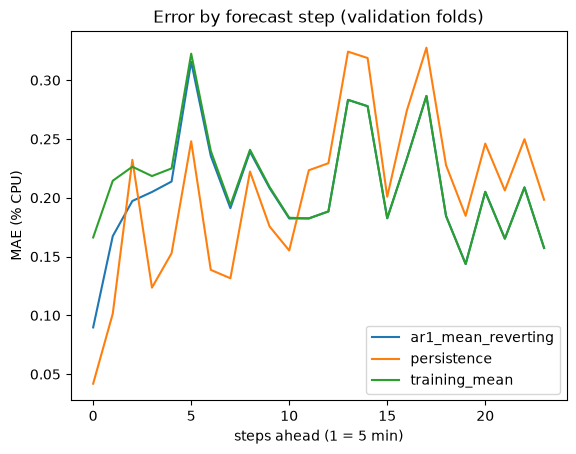

In [8]:
import matplotlib.pyplot as plt
for name in ["ar1_mean_reverting", "persistence", "training_mean"]:
    _, e = evaluate_forecaster(train, candidates[name], T)
    pd.Series(abs(e).mean(axis=0)).plot(label=name)
plt.xlabel("steps ahead (1 = 5 min)"); plt.ylabel("MAE (% CPU)"); plt.legend()
plt.title("Error by forecast step (validation folds)")
plt.savefig("../reports/figures/model_error_by_step.png", dpi=120, bbox_inches="tight")

In [9]:
pd.concat({"primary": run(), "sensitivity": run(min_train_size=30, step=6)}, axis=1) \
  .to_csv("../reports/model_comparison.csv")

In [10]:
d = collect_predictions(train, candidates["ar1_mean_reverting"], T)
print(d["error"].quantile([0.5, 0.8, 0.9, 0.95, 0.99]).round(3))

d["horizon"] = pd.cut(d["step_ahead"], [-1, 5, 11, 23],
                      labels=["0-5 (<=30 min)", "6-11 (30-60 min)", "12-23 (1-2 h)"])
print(d.groupby("horizon", observed=True)["error"]
        .quantile([0.5, 0.9, 0.95]).unstack().round(3))

0.50   -0.074
0.80    0.214
0.90    0.396
0.95    0.456
0.99    0.522
Name: error, dtype: float64
                   0.50   0.90   0.95
horizon                              
0-5 (<=30 min)   -0.047  0.264  0.383
6-11 (30-60 min) -0.019  0.444  0.467
12-23 (1-2 h)    -0.125  0.284  0.416
